# Deep Learning HW2 Part 2
Author: Daniel Bond

In [3]:
from google.colab import drive
drive.mount("/content/drive")

!unzip -q -o /content/drive/MyDrive/Archive.zip -d /content -x "__MACOSX/*"
!ls /content && ls /content/train | wc -l && ls /content/test | wc -l

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Archive.zip  drive  sample_data  test  test.csv  train	train.csv
12260
18673


In [2]:
!pip install -q iterative-stratification lightning wandb timm grad-cam

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 45.0/45.0 kB 3.4 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.5/44.5 kB 4.6 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 849.3/849.3 kB 58.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 983.4/983.4 kB 56.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 853.0/853.0 kB 59.7 MB/s eta 0:00:00


In [4]:
import random
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

from iterstrat.ml_stratifiers import MultilabelStratifiedKFold
from sklearn.metrics import f1_score

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision.transforms import v2 as T
import timm
import lightning as L
from lightning.pytorch.loggers import WandbLogger
from lightning.pytorch.callbacks import ModelCheckpoint

seed = 67
L.seed_everything(seed)

DATA_DIR = Path(".")
TRAIN_IMG_DIR = DATA_DIR / "train"
TEST_IMG_DIR = DATA_DIR / "test"
LABELS = ["Cat", "Dog", "Moris", "Motya", "Biatrix"]

train_df = pd.read_csv(DATA_DIR / "train.csv")
test_df = pd.read_csv(DATA_DIR / "test.csv")

print(f"train: {train_df.shape}, test: {test_df.shape}")
print(f"torch {torch.__version__}, timm {timm.__version__}, mps available: {torch.backends.mps.is_available()}")

INFO: Seed set to 67
INFO:lightning.fabric.utilities.seed:Seed set to 67


train: (12260, 6), test: (18673, 1)
torch 2.11.0+cu130, timm 1.0.30, mps available: False


## Validation
As shown in Part 1, the three named pets have only 41-56 positives each, so a random split would give a very noisy score - multilabel-stratified K-Fold is needed, otherwise a fold can end up with no `Moris`, `Motya` or `Biatrix`. The strategy is multilabel-stratified 5-Fold, and the same folds are saved and reused for every experiment so the results are comparable.

In [5]:
mskf = MultilabelStratifiedKFold(n_splits=5, shuffle=True, random_state=seed)

train_df["fold"] = -1
for fold, (_, val_idx) in enumerate(mskf.split(train_df, train_df[LABELS])):
    train_df.loc[val_idx, "fold"] = fold
train_df[["image_id", "fold"]].to_csv("folds.csv", index=False)

train_df.groupby("fold")[LABELS].sum().assign(images=train_df["fold"].value_counts().sort_index())

,Cat,Dog,Moris,Motya,Biatrix,images
fold,,,,,,
0,1016,1005,11,9,8,2452
1,1016,1005,12,9,8,2452
2,1015,1005,11,8,8,2452
3,1015,1005,11,8,8,2452
4,1015,1005,11,8,9,2452


Every fold gets 8-12 images of each pet and the same Cat/Dog ratio, so per-fold macro F1 is comparable between folds.

### Correlation with leaderboards
I expect CV to be close to the leaderboard, but with visible noise.

Why:

Train and test images come from the same sources (generic cats/dogs, other animals, pet photos), as seen in Part 1, and multilabel stratification will keep every fold close to the overall distribution.

Why not:

Public LB is 33% of test, 20-30 positives per pet, so mistakes will shift macro F1 noticeably. Pet photos are near-identical, and the random split can put them in both train and validation, which makes CV optimistic on the pet classes. Per-class thresholds need tuning, which may not transfer directly to test. Test is 1.5x larger than train and could contain images not similar to anything in train.

### Adversarial validation
Will be done after the model exists

## CNN model
`efficientnet_b4.ra2_in1k` - ImageNet-1k weights only, trained at 320 and evaluated at 384, which is close to the 450x375 images. The head outputs 5 logits with sigmoid + BCE loss. Training is done with Lightning and logged to W&B.

In [6]:
MODEL_NAME = "efficientnet_b4.ra2_in1k"
IMG_SIZE = (320, 384)
BATCH_SIZE = 32
EPOCHS = 10
LR = 3e-4

pcfg = timm.models.get_pretrained_cfg(MODEL_NAME)

train_tf = T.Compose([
    T.ToImage(),
    T.RandomResizedCrop(IMG_SIZE, scale=(0.7, 1.0), ratio=(1.0, 1.4)),
    T.RandomHorizontalFlip(),
    T.ToDtype(torch.float32, scale=True),
    T.Normalize(pcfg.mean, pcfg.std),
])
val_tf = T.Compose([
    T.ToImage(),
    T.Resize(IMG_SIZE),
    T.ToDtype(torch.float32, scale=True),
    T.Normalize(pcfg.mean, pcfg.std),
])

In [7]:
class PetDataset(Dataset):
    def __init__(self, df, img_dir, tf):
        self.df, self.img_dir, self.tf = df.reset_index(drop=True), img_dir, tf

    def __len__(self):
        return len(self.df)

    def __getitem__(self, i):
        row = self.df.iloc[i]
        img = Image.open(self.img_dir / f"{row.image_id}.jpg").convert("RGB")
        y = torch.tensor(row[LABELS].to_numpy(np.float32)) if LABELS[0] in row else torch.zeros(len(LABELS))
        return self.tf(img), y

In [8]:
class SpatialAttention(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv = nn.Conv2d(2, 1, kernel_size=7, padding=3)

    def forward(self, x):
        pooled = torch.cat([x.mean(dim=1, keepdim=True), x.amax(dim=1, keepdim=True)], dim=1)
        return x * torch.sigmoid(self.conv(pooled))


class LitPets(L.LightningModule):
    def __init__(self, lr=LR, spatial_attention=False):
        super().__init__()
        self.save_hyperparameters()
        self.net = timm.create_model(MODEL_NAME, pretrained=True, num_classes=len(LABELS))
        if spatial_attention:
            self.net.bn2 = nn.Sequential(self.net.bn2, SpatialAttention())
        self.loss_fn = nn.BCEWithLogitsLoss()
        self.val_probs, self.val_targets = [], []

    def forward(self, x):
        return self.net(x)

    def training_step(self, batch, batch_idx):
        x, y = batch
        loss = self.loss_fn(self(x), y)
        self.log("train/loss", loss, prog_bar=True)
        return loss

    def validation_step(self, batch, batch_idx):
        x, y = batch
        logits = self(x)
        self.log("val/loss", self.loss_fn(logits, y), prog_bar=True)
        self.val_probs.append(torch.sigmoid(logits).float().cpu())
        self.val_targets.append(y.cpu())

    def on_validation_epoch_end(self):
        probs, y = torch.cat(self.val_probs).numpy(), torch.cat(self.val_targets).numpy()
        self.val_probs, self.val_targets = [], []
        self.log("val/macro_f1", f1_score(y, probs > 0.5, average="macro", zero_division=0), prog_bar=True)

    def predict_step(self, batch, batch_idx):
        x, _ = batch
        return torch.sigmoid(self(x)).float()

    def configure_optimizers(self):
      opt = torch.optim.AdamW(self.parameters(), lr=self.hparams.lr)
      sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=self.trainer.max_epochs)
      return [opt], [sched]

In [ ]:
FOLD = 0
tr, va = train_df[train_df["fold"] != FOLD], train_df[train_df["fold"] == FOLD]
train_dl = DataLoader(PetDataset(tr, TRAIN_IMG_DIR, train_tf), batch_size=BATCH_SIZE, shuffle=True, num_workers=2)
val_dl = DataLoader(PetDataset(va, TRAIN_IMG_DIR, val_tf), batch_size=BATCH_SIZE, num_workers=2)

model = LitPets()
logger = WandbLogger(project="dl-hw2-cats-and-dogs", name=f"b4_baseline_fold{FOLD}")
logger.watch(model, log="gradients")
ckpt = ModelCheckpoint(monitor="val/macro_f1", mode="max")

trainer = L.Trainer(max_epochs=EPOCHS, accelerator="auto", devices=1, precision="16-mixed",
                    logger=logger, callbacks=[ckpt])
trainer.fit(model, train_dl, val_dl)
print(f"CV macro F1 (fold {FOLD}): {ckpt.best_model_score:.4f}")

/usr/local/lib/python3.13/dist-packages/lightning/pytorch/loggers/wandb.py:400: There is a wandb run already in progress and newly created instances of `WandbLogger` will reuse this run. If this is not desired, call `wandb.finish()` before instantiating `WandbLogger`.
wandb: logging graph, to disable use `wandb.watch(log_graph=False)`
INFO: Using 16bit Automatic Mixed Precision (AMP)
INFO:lightning.pytorch.utilities.rank_zero:Using 16bit Automatic Mixed Precision (AMP)
INFO: GPU available: True (cuda), used: True
INFO:lightning.pytorch.utilities.rank_zero:GPU available: True (cuda), used: True
INFO: TPU available: False, using: 0 TPU cores
INFO:lightning.pytorch.utilities.rank_zero:TPU available: False, using: 0 TPU cores
INFO: 💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
INFO:lightning.pytorch.utilities

┏━━━┳━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━┳━━━━━━━┳━━━━━━━┓
┃   ┃ Name    ┃ Type              ┃ Params ┃ Mode  ┃ FLOPs ┃
┡━━━╇━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━╇━━━━━━━╇━━━━━━━┩
│ 0 │ net     │ EfficientNet      │ 17.6 M │ train │     0 │
│ 1 │ loss_fn │ BCEWithLogitsLoss │      0 │ train │     0 │
└───┴─────────┴───────────────────┴────────┴───────┴───────┘

Trainable params: 17.6 M                                                                                           
Non-trainable params: 0                                                                                            
Total params: 17.6 M                                                                                               
Total estimated model params size (MB): 70.230                                                                     
Modules in train mode: 654                                                                                         
Modules in eval mode: 0                                                                                            
Total FLOPs: 0

Output()

/usr/local/lib/python3.13/dist-packages/lightning/pytorch/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)`
is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.

/usr/local/lib/python3.13/dist-packages/lightning/pytorch/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)`
is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.

INFO: `Trainer.fit` stopped: `max_epochs=10` reached.
INFO:lightning.pytorch.utilities.rank_zero:`Trainer.fit` stopped: `max_epochs=10` reached.


CV macro F1 (fold 0): 0.9585


In [ ]:
test_dl = DataLoader(PetDataset(test_df, TEST_IMG_DIR, val_tf), batch_size=BATCH_SIZE, num_workers=2)
test_probs = torch.cat(trainer.predict(model, test_dl, ckpt_path="best")).numpy()

sub = pd.DataFrame((test_probs > 0.5).astype(int), columns=LABELS)
sub.insert(0, "image_id", test_df["image_id"])
sub.to_csv("sub_b4_baseline.csv", index=False)
sub[LABELS].mean().round(4)

INFO: Restoring states from the checkpoint path at ./dl-hw2-cats-and-dogs/o4bmczy1/checkpoints/epoch=2-step=921.ckpt
INFO:lightning.pytorch.utilities.rank_zero:Restoring states from the checkpoint path at ./dl-hw2-cats-and-dogs/o4bmczy1/checkpoints/epoch=2-step=921.ckpt
INFO: LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
INFO:lightning.pytorch.accelerators.cuda:LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
INFO: Loaded model weights from the checkpoint at ./dl-hw2-cats-and-dogs/o4bmczy1/checkpoints/epoch=2-step=921.ckpt
INFO:lightning.pytorch.utilities.rank_zero:Loaded model weights from the checkpoint at ./dl-hw2-cats-and-dogs/o4bmczy1/checkpoints/epoch=2-step=921.ckpt
/usr/local/lib/python3.13/dist-packages/lightning/pytorch/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.


Output()

,0
Cat,0.4163
Dog,0.4075
Moris,0.0089
Motya,0.0070
Biatrix,0.0071


In [ ]:
ckpt.best_model_score.item(), ckpt.best_model_path

(0.9585383534431458,
 './dl-hw2-cats-and-dogs/o4bmczy1/checkpoints/epoch=2-step=921.ckpt')

In [ ]:
val_probs = torch.cat(trainer.predict(model, val_dl, ckpt_path="best")).numpy()
per_class = f1_score(va[LABELS].to_numpy(), val_probs > 0.5, average=None, zero_division=0)
pd.Series(per_class, index=LABELS).round(4)

INFO: Restoring states from the checkpoint path at ./dl-hw2-cats-and-dogs/o4bmczy1/checkpoints/epoch=2-step=921.ckpt
INFO:lightning.pytorch.utilities.rank_zero:Restoring states from the checkpoint path at ./dl-hw2-cats-and-dogs/o4bmczy1/checkpoints/epoch=2-step=921.ckpt
INFO: LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
INFO:lightning.pytorch.accelerators.cuda:LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
INFO: Loaded model weights from the checkpoint at ./dl-hw2-cats-and-dogs/o4bmczy1/checkpoints/epoch=2-step=921.ckpt
INFO:lightning.pytorch.utilities.rank_zero:Loaded model weights from the checkpoint at ./dl-hw2-cats-and-dogs/o4bmczy1/checkpoints/epoch=2-step=921.ckpt
/usr/local/lib/python3.13/dist-packages/lightning/pytorch/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.


Output()

,0
Cat,0.9916
Dog,0.9915
Moris,0.9524
Motya,1.0000
Biatrix,0.8571


In [9]:
test_dl = DataLoader(PetDataset(test_df, TEST_IMG_DIR, val_tf), batch_size=BATCH_SIZE, num_workers=2)

def train_fold(fold, name="b4_5fold", **model_kwargs):
    tr, va = train_df[train_df["fold"] != fold], train_df[train_df["fold"] == fold]
    train_dl = DataLoader(PetDataset(tr, TRAIN_IMG_DIR, train_tf), batch_size=BATCH_SIZE, shuffle=True, num_workers=2)
    val_dl = DataLoader(PetDataset(va, TRAIN_IMG_DIR, val_tf), batch_size=BATCH_SIZE, num_workers=2)

    model = LitPets(**model_kwargs)
    logger = WandbLogger(project="dl-hw2-cats-and-dogs", name=f"{name}_fold{fold}", group=name)
    logger.watch(model, log="gradients")
    ckpt = ModelCheckpoint(monitor="val/macro_f1", mode="max")
    trainer = L.Trainer(max_epochs=EPOCHS, accelerator="auto", devices=1, precision="16-mixed",
                        logger=logger, callbacks=[ckpt])
    trainer.fit(model, train_dl, val_dl)

    val_probs = torch.cat(trainer.predict(model, val_dl, ckpt_path="best")).numpy()
    test_probs = torch.cat(trainer.predict(model, test_dl, ckpt_path="best")).numpy()
    logger.experiment.finish()
    return val_probs, test_probs, ckpt.best_model_path

In [ ]:
oof = np.zeros((len(train_df), len(LABELS)))
test_pred = np.zeros((len(test_df), len(LABELS)))

for fold in range(5):
    val_probs, test_probs, _ = train_fold(fold)
    oof[(train_df["fold"] == fold).to_numpy()] = val_probs
    test_pred += test_probs / 5
    np.save("/content/drive/MyDrive/oof.npy", oof)
    np.save("/content/drive/MyDrive/test_pred.npy", test_pred)

Predicting ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 584/584 0:01:53 • 0:00:00 5.18it/s

epoch,▁▁▁▁▁▂▂▂▂▃▃▃▃▃▃▃▃▃▄▄▄▄▅▅▅▅▅▅▆▆▆▆▆▆▆▇████
train/loss,▇█▁▁▁▁▁▁▁▁▁▃▁▃▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
trainer/global_step,▁▁▁▁▁▂▂▂▂▂▂▃▃▃▃▃▄▄▄▄▄▄▅▅▅▅▅▅▅▆▆▆▆▆▆▇▇▇▇█
val/loss,█▃▃▅▅▂▂▁▁▁
val/macro_f1,▁▂█▇▅▅▇▅▅▆
epoch,9
train/loss,0.00011
trainer/global_step,3069
val/loss,0.00589
val/macro_f1,0.95206


In [10]:
# Loading already saved progress to avoid rerun for 4+ hours
OUT_DIR = Path("/content/drive/MyDrive")
oof = np.load(OUT_DIR / "oof.npy")
test_pred = np.load(OUT_DIR / "test_pred.npy")

In [11]:
y = train_df[LABELS].to_numpy()
folds = train_df["fold"].to_numpy()
fold_f1 = [f1_score(y[folds == k], oof[folds == k] > 0.5, average="macro") for k in range(5)]
print(f"CV macro F1 @0.5: {np.mean(fold_f1):.4f} ± {np.std(fold_f1):.4f}")

grid = np.arange(0.05, 0.96, 0.05)
thresholds = np.array([grid[np.argmax([f1_score(y[:, c], oof[:, c] > t) for t in grid])] for c in range(len(LABELS))])
print("thresholds:", dict(zip(LABELS, thresholds.round(2))))
print(f"CV macro F1 tuned: {f1_score(y, oof > thresholds, average='macro'):.4f}")

for name, thr in [("b4_5fold", 0.5), ("b4_5fold_tuned", thresholds)]:
    sub = pd.DataFrame((test_pred > thr).astype(int), columns=LABELS)
    sub.insert(0, "image_id", test_df["image_id"])
    sub.to_csv(f"{name}.csv", index=False)

CV macro F1 @0.5: 0.9717 ± 0.0161
thresholds: {'Cat': np.float64(0.55), 'Dog': np.float64(0.35), 'Moris': np.float64(0.3), 'Motya': np.float64(0.25), 'Biatrix': np.float64(0.35)}
CV macro F1 tuned: 0.9753


### Custom block
Spatial attention. Same fold and training setup as the plain B4.

In [12]:
val_probs, test_probs, ckpt_custom = train_fold(0, "b4_custom", spatial_attention=True)
np.save(OUT_DIR / "val_b4_custom_fold0.npy", val_probs)
np.save(OUT_DIR / "test_b4_custom_fold0.npy", test_probs)

va = folds == 0
print(f"b4:        fold 0 macro F1 = {f1_score(y[va], oof[va] > 0.5, average='macro'):.4f}")
print(f"b4_custom: fold 0 macro F1 = {f1_score(y[va], val_probs > 0.5, average='macro'):.4f}")

sub = pd.DataFrame((test_probs > 0.5).astype(int), columns=LABELS)
sub.insert(0, "image_id", test_df["image_id"])
sub.to_csv("sub_b4_custom.csv", index=False)

model.safetensors: reconstructing file:   0%|          |  0.00B / 77.9MB            

model.safetensors: downloading bytes:           |  0.00B            

wandb: WARNING The anonymous setting has no effect and will be removed in a future version.
/usr/local/lib/python3.13/dist-packages/notebook/notebookapp.py:191: SyntaxWarning: invalid escape sequence '\/'
  | |_| | '_ \/ _` / _` |  _/ -_)
wandb: (1) Create a W&B account
wandb: (2) Use an existing W&B account
wandb: (3) Don't visualize my results


wandb: Enter your choice: 2


wandb: You chose 'Use an existing W&B account'
wandb: Logging into https://api.wandb.ai. (Learn how to deploy a W&B server locally: https://wandb.me/wandb-server)
wandb: Create a new API key at: https://wandb.ai/authorize?ref=models
wandb: Store your API key securely and do not share it.


...

Output()

INFO: Restoring states from the checkpoint path at ./dl-hw2-cats-and-dogs/e6ybvb4i/checkpoints/epoch=7-step=2456.ckpt
INFO:lightning.pytorch.utilities.rank_zero:Restoring states from the checkpoint path at ./dl-hw2-cats-and-dogs/e6ybvb4i/checkpoints/epoch=7-step=2456.ckpt
INFO: LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
INFO:lightning.pytorch.accelerators.cuda:LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
INFO: Loaded model weights from the checkpoint at ./dl-hw2-cats-and-dogs/e6ybvb4i/checkpoints/epoch=7-step=2456.ckpt
INFO:lightning.pytorch.utilities.rank_zero:Loaded model weights from the checkpoint at ./dl-hw2-cats-and-dogs/e6ybvb4i/checkpoints/epoch=7-step=2456.ckpt


Output()

epoch,▁▁▁▂▂▂▂▃▃▃▃▃▃▃▃▃▃▄▄▄▅▅▆▆▆▆▆▆▆▆▆▆▇▇▇▇▇███
train/loss,█▂▃▂▁▁▁▁▁▁▁▁▂▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
trainer/global_step,▁▁▁▁▂▂▂▂▂▃▃▃▃▃▃▄▄▄▄▄▄▅▅▅▅▅▅▆▆▆▆▆▆▆▇▇▇▇▇█
val/loss,▅█▇▁▇▄▃▄▅▄
val/macro_f1,▁▆█▇████▇█
epoch,9
train/loss,2e-05
trainer/global_step,3069
val/loss,0.00951
val/macro_f1,0.95291


b4:        fold 0 macro F1 = 0.9647
b4_custom: fold 0 macro F1 = 0.9530


### GradCAM


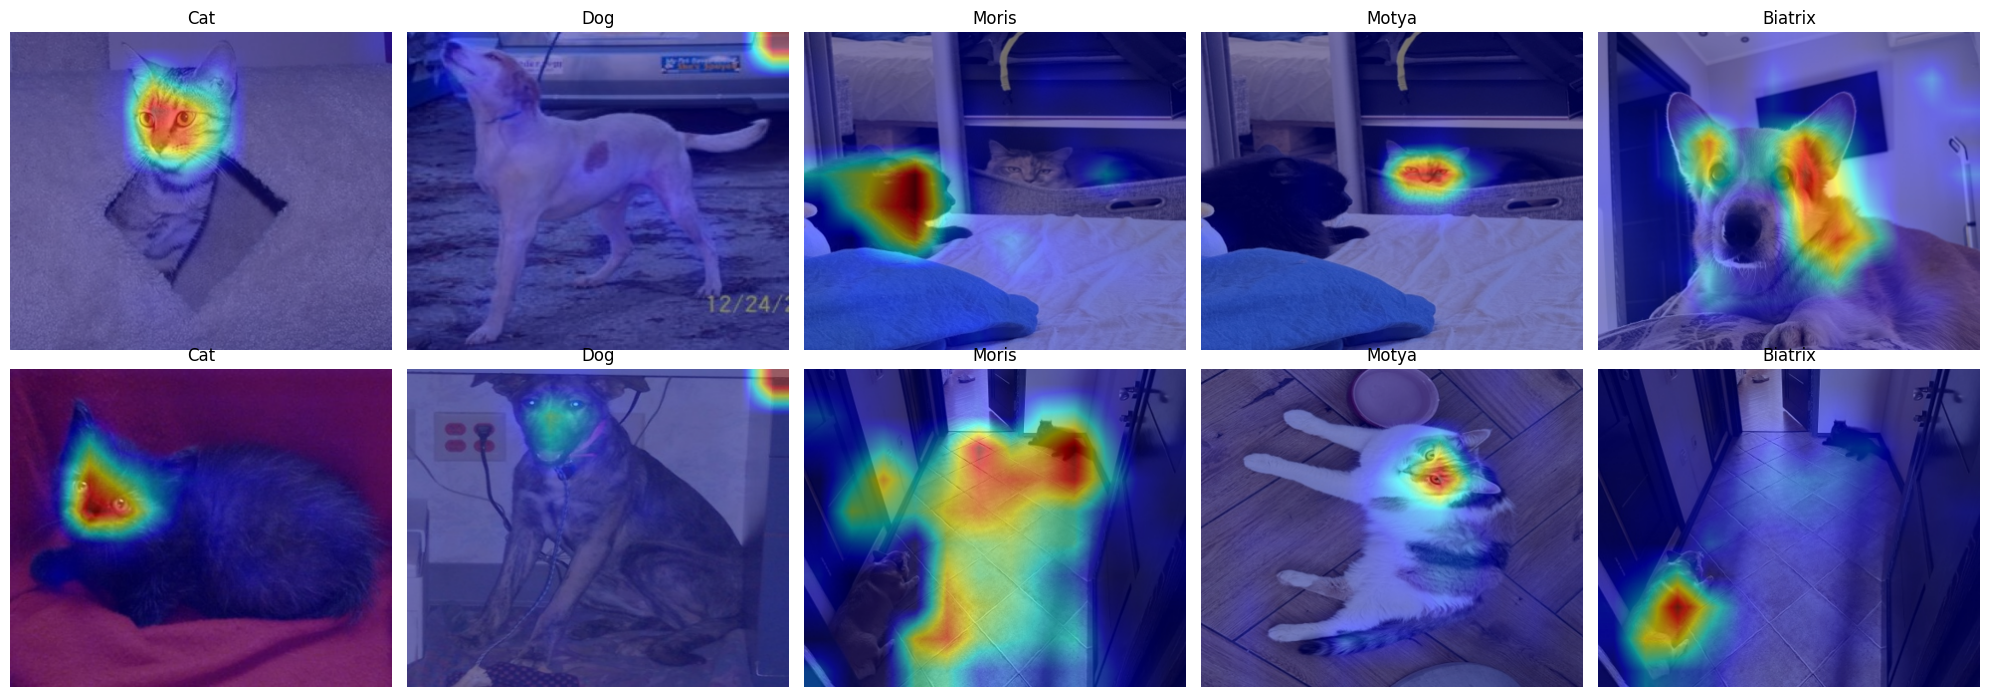

In [13]:
from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget
from pytorch_grad_cam.utils.image import show_cam_on_image

va = folds == 0
cam_model = LitPets.load_from_checkpoint(ckpt_custom, map_location="cpu").eval()
cam = GradCAM(model=cam_model, target_layers=[cam_model.net.bn2])

va_df = train_df[va]
fig, axes = plt.subplots(2, len(LABELS), figsize=(20, 7))
for col, label in enumerate(LABELS):
    for row in range(2):
        img_id = va_df[va_df[label] == 1].image_id.iloc[row]
        img = Image.open(TRAIN_IMG_DIR / f"{img_id}.jpg").convert("RGB")
        heat = cam(input_tensor=val_tf(img).unsqueeze(0), targets=[ClassifierOutputTarget(col)])[0]
        rgb = np.asarray(img.resize((IMG_SIZE[1], IMG_SIZE[0])), dtype=np.float32) / 255
        axes[row, col].imshow(show_cam_on_image(rgb, heat, use_rgb=True))
        axes[row, col].set_title(label)
        axes[row, col].axis("off")
plt.tight_layout()
plt.show()

Looks like the model differentiates animals by focusing on their heads. `Dog` attention maps look a bit weird. Individual pet predictions show how model focuses on individual pets per class - on the same image it has different attention maps for both cats

## Ensembling
Averaging of previous results + tuned threshold from 5-fold run

In [14]:
OUT_DIR = Path("/content/drive/MyDrive")
thresholds = np.array([0.55, 0.35, 0.30, 0.25, 0.35])

y = train_df[LABELS].to_numpy()
va = (train_df["fold"] == 0).to_numpy()
p_b4 = np.load(OUT_DIR / "oof.npy")[va]
p_custom = np.load(OUT_DIR / "val_b4_custom_fold0.npy")
p_ens = (p_b4 + p_custom) / 2

for name, p in [("b4", p_b4), ("b4_custom", p_custom), ("ensemble", p_ens)]:
    f05 = f1_score(y[va], p > 0.5, average="macro")
    ftuned = f1_score(y[va], p > thresholds, average="macro")
    print(f"{name:10} fold 0 macro F1: {f05:.4f} @0.5, {ftuned:.4f} tuned")

ens_test = (np.load(OUT_DIR / "test_pred.npy") + np.load(OUT_DIR / "test_b4_custom_fold0.npy")) / 2
for name, thr in [("sub_ensemble", 0.5), ("sub_ensemble_tuned", thresholds)]:
    sub = pd.DataFrame((ens_test > thr).astype(int), columns=LABELS)
    sub.insert(0, "image_id", test_df["image_id"])
    sub.to_csv(OUT_DIR / f"{name}.csv", index=False)

b4         fold 0 macro F1: 0.9647 @0.5, 0.9649 tuned
b4_custom  fold 0 macro F1: 0.9530 @0.5, 0.9643 tuned
ensemble   fold 0 macro F1: 0.9529 @0.5, 0.9767 tuned


### Results
| Experiment | CV macro F1 | Public LB |
|---|---|---|
| b4_baseline | 0.9435 | 0.92381 |
| b4_cosine | 0.9585 | 0.91851 |
| b4_5fold | 0.9717 | 0.94541 |
| b4_5fold_tuned | 0.9753 | 0.95743 |
| b4_custom | 0.9530 | 0.92514 |
| b4_ensemble | 0.9529 | 0.93135 |
| b4_ensemble_tuned | 0.9767 | 0.95498 |

## Adversarial validation
Can train and test images be distinguished?

In [15]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import roc_auc_score

feat_model = timm.create_model(MODEL_NAME, pretrained=True, num_classes=0).cuda().eval()

def features(df, img_dir):
    dl = DataLoader(PetDataset(df, img_dir, val_tf), batch_size=64, num_workers=2)
    with torch.no_grad(), torch.autocast("cuda"):
        return torch.cat([feat_model(x.cuda()).float().cpu() for x, _ in dl]).numpy()

X_adv = np.vstack([features(train_df, TRAIN_IMG_DIR), features(test_df, TEST_IMG_DIR)])
y_adv = np.r_[np.zeros(len(train_df)), np.ones(len(test_df))]
p_adv = cross_val_predict(LogisticRegression(max_iter=1000), X_adv, y_adv, cv=5, method="predict_proba")[:, 1]
print(f"Adversarial AUC: {roc_auc_score(y_adv, p_adv):.4f}")

Adversarial AUC: 0.5029


No - AUC ~0.5 means that the images are sampled from roughly the same distribution.